# Rutas Mínimas con Distintas Colas de Prioridad en Redes Viales Urbanas del Cusco
### Comparativa de Algoritmos de Dijkstra Parametrizado, Búsqueda Heurística A* y Colas de Prioridad

**Universidad Nacional de San Antonio Abad del Cusco (UNSAAC)**  
**Facultad de Ingeniería Eléctrica, Electrónica, Informática y Mecánica**  
**Escuela Profesional de Ingeniería Informática y de Sistemas**  
**Asignatura:** Algoritmos Avanzados (Semestre 2026-II)  
**Docente Revisor:** Ing. Héctor Eduardo Ugarte Rojas  
**Grupo 5:** Choquenaira Q. Noe, Porroa S. Yeni Ruth, Quispe R. Romario, Yaranga A. Aldo  

---
### Objetivos y Alcance del Proyecto
1. **Modelar y Representar:** Usar una instancia ilustrativa dirigida de seis nodos: nombres geográficos, pero topología, coordenadas, longitudes, sentidos y pendientes supuestos. El caso OSM y las mediciones canónicas se estudian por separado en `python/` (véase `docs/DATOS_Y_MODELO.md`).
2. **Diseñar e Implementar:** Implementar de forma modular e independiente tres estructuras de cola de prioridad pura con `Decrease-Key`:
   - **Binary Min-Heap Indexado:** Mapeo inverso posicional hash en $O(1)$ para actualización en $O(\log V)$.
   - **4-ary Heap Contiguo ($d=4$):** Montículo cuaternario almacenado en una lista, con altura $O(\log_4 V)$. No se midió la caché del procesador.
   - **Fibonacci Heap Dinámico:** Bosque de árboles enlazados con listas circulares dobles, logrando `Decrease-Key` en $O(1)$ amortizado.
3. **Evaluar e Integrar:** Integrar el **Algoritmo de Dijkstra Parametrizado** y el **Algoritmo A*** ($A^*$), verificando equivalencia matemática, evaluando la función de impedancia (distancia pura vs tiempo con pendiente) y comparando el rendimiento empírico.

**Recorrido:** 1) preparación; 2) modelo y precondiciones; 3) las tres colas, cada una en su propia celda; 4) Dijkstra; 5) A*; 6–7) validación y comparación; 8–9) visualización; 10) pruebas; 11) consulta modificable; 12) experimento exploratorio; 13) discusión. Ejecute las celdas en orden.

**Procedencia:** Las salidas guardadas se regeneraron con un kernel Jupyter local de Python 3.12 el 05/11/2026, con dependencias ya instaladas. La celda de instalación `%pip` no se ejecutó localmente. Esto no acredita una ejecución en el servicio Google Colab. El notebook no reproduce los resultados OSM ni el banco canónico del informe.


## 1. Configuración del Entorno y Dependencias
Instalamos e importamos librerías estándar y científicas:
- `networkx`: Oráculo de referencia para contrastar resultados exactos.
- `graphviz`: Generación y renderizado de diagramas de grafos vectoriales SVG.
- `matplotlib`: Visualizaciones estadísticas y curvas de escalabilidad.


In [ ]:
# Instalación de dependencias (en Google Colab)
%pip install -q networkx graphviz matplotlib


### Importaciones y visualización opcional
El ejecutable `dot` solo es necesario para el SVG; el cálculo de rutas no depende de él.


In [1]:
import math
import os
import shutil
import time
import random
import statistics
from dataclasses import dataclass
from typing import Dict, List, Tuple, Any, Optional, Set, Callable, Hashable

import matplotlib.pyplot as plt
import networkx as nx
import graphviz

# Detecta Graphviz en Windows aunque VS Code conserve un PATH anterior.
if os.name == "nt" and shutil.which("dot") is None:
    for graphviz_bin in (
        os.path.join(os.environ.get("ProgramFiles", r"C:\Program Files"), "Graphviz", "bin"),
        os.path.join(os.environ.get("ProgramFiles(x86)", r"C:\Program Files (x86)"), "Graphviz", "bin"),
    ):
        if os.path.isfile(os.path.join(graphviz_bin, "dot.exe")):
            os.environ["PATH"] = graphviz_bin + os.pathsep + os.environ.get("PATH", "")
            break

graphviz_available = shutil.which("dot") is not None

# Configuración estética
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
print(f"Entorno configurado: NetworkX y Matplotlib; ejecutable Graphviz: {'disponible' if graphviz_available else 'no disponible'}.")


Entorno configurado: NetworkX y Matplotlib; ejecutable Graphviz: disponible.


## 2. Red Vial del Centro Histórico del Cusco y Función de Impedancia

### Modelo Topográfico Andino y Restricciones Urbanas
En el Centro Histórico de Cusco, el ruteo no depende únicamente de la distancia euclidiana o física en metros:
1. **Sentido de circulación:** Se modela cada tramo como arista dirigida, sin afirmar que el sentido coincide con la calle real.
2. **Tipo de calle:** Las velocidades nominales son supuestos del ejemplo.
3. **Pendiente:** Los porcentajes y el factor de sensibilidad son hipotéticos; no proceden de un levantamiento topográfico ni de una calibración de tiempos de viaje.

### Función de Impedancia (Tiempo de Viaje Ponderado):
$$C(u, v) = T_{\text{base}}(u, v) \cdot \left(1 + \alpha \cdot \max\left(0, \frac{\text{pendiente}(u, v)}{100}\right)\right)$$
donde $T_{\text{base}}(u, v) = \frac{\text{longitud}(u, v)}{V_{\text{nominal}}}$ y $\alpha = 2.5$ es un parámetro de escenario, no un coeficiente medido. Los costos temporales se redondean a centésimas de segundo.


### 2.1. Costos de un tramo
`RoadSegment` guarda atributos del ejemplo. `CuscoCostModel` devuelve metros o segundos según la métrica; las velocidades y pendientes son supuestas.


In [2]:
# Describe un tramo dirigido con sus atributos físicos y viales.
@dataclass
class RoadSegment:
    origin: str
    destination: str
    length_m: float
    street_type: str
    gradient_pct: float
    street_name: str


# Centraliza las reglas que convierten cada tramo en distancia o tiempo.
class CuscoCostModel:
    NOMINAL_SPEED_KMH = {
        'avenida': 35.0,
        'calle_residencial': 25.0,
        'calle_centro': 15.0,
        'peatonal': 8.0
    }
    ALPHA_SLOPE = 2.5

    # La métrica temporal aplica velocidad nominal y penalización por pendiente.
    @classmethod
    def calculate_cost(cls, segment: RoadSegment, metric: str = 'time') -> float:
        if metric == 'distance':
            return segment.length_m
        speed_kmh = cls.NOMINAL_SPEED_KMH.get(segment.street_type, 20.0)
        speed_ms = speed_kmh / 3.6
        t_base_sec = segment.length_m / speed_ms
        slope_penalty = 1.0 + cls.ALPHA_SLOPE * max(0.0, segment.gradient_pct / 100.0)
        return round(t_base_sec * slope_penalty, 2)


### 2.2. Instancia ilustrativa
Seis lugares identifican los vértices y nueve tramos dirigidos forman la red. Las conexiones, sentidos, coordenadas, longitudes y pendientes no son un levantamiento vial.


In [3]:
# Lugares con nombres reales usados como nodos del ejemplo esquemático
NODES_CUSCO = {
    "A": "Plaza Mayor del Cusco",
    "B": "Plaza Regocijo (Cusipata)",
    "C": "Qorikancha (Santo Domingo)",
    "D": "Plaza San Francisco",
    "E": "Mercado Central San Pedro",
    "F": "Plazoleta Limacpampa"
}

# Coordenadas ilustrativas (x, y), no georreferenciadas ni medidas
COORDS_CUSCO = {
    "A": (0.0, 0.0),       # Plaza Mayor
    "B": (-120.0, -10.0),  # Plaza Regocijo
    "C": (180.0, -250.0),  # Qorikancha
    "D": (-310.0, -80.0),  # Plaza San Francisco
    "E": (-480.0, -320.0), # Mercado Central San Pedro
    "F": (350.0, -420.0)   # Plazoleta Limacpampa
}

# Aristas ilustrativas: longitudes, pendientes, conexiones y sentidos supuestos
ROAD_SEGMENTS = [
    RoadSegment("A", "B", 180.0, "calle_centro", 1.5, "Calle Espaderos / Portal Carnicerías"),
    RoadSegment("A", "C", 450.0, "calle_centro", -2.0, "Calle Loreto / Pampa del Castillo"),
    RoadSegment("B", "D", 220.0, "calle_centro", 3.0, "Calle Garcilaso / Calle Marqués"),
    RoadSegment("B", "C", 400.0, "calle_centro", -1.0, "Calle San Bernardo / Almagro"),
    RoadSegment("C", "F", 350.0, "avenida", 0.5, "Calle Ahuacpinta / Limacpampa Grande"),
    RoadSegment("C", "E", 600.0, "calle_centro", 2.0, "Calle Matará / Tres Cruces de Oro"),
    RoadSegment("D", "E", 250.0, "calle_centro", 2.5, "Calle Santa Clara / Arco Santa Clara"),
    RoadSegment("D", "C", 500.0, "calle_centro", -2.5, "Calle Marqués / Mantas"),
    RoadSegment("E", "F", 700.0, "avenida", -1.0, "Calle Nueva Baja / Av. Tullumayo")
]


### 2.3. Grafo y precondiciones
Convertimos los tramos en listas de adyacencia. Antes de Dijkstra o A* se comprueba origen, nodos, destinos y pesos numéricos, finitos y no negativos.


In [4]:
# Convierte los tramos en la lista de adyacencia que consumen Dijkstra y A*.
def get_cusco_adjacency(metric: str = "distance") -> Tuple[List[str], Dict[str, List[Tuple[str, float]]]]:
    nodes = list(NODES_CUSCO.keys())
    adj = {v: [] for v in nodes}
    for seg in ROAD_SEGMENTS:
        cost = CuscoCostModel.calculate_cost(seg, metric=metric)
        adj[seg.origin].append((seg.destination, cost))
    return nodes, adj


# Comprueba que el origen, los nodos y los pesos sean válidos antes de buscar rutas.
def validate_graph(nodes: List[str], adj: Dict[str, List[Tuple[str, float]]], source: str) -> None:
    """Módulo de validación defensiva de entradas viales."""
    if not nodes:
        raise ValueError("El conjunto de nodos no puede estar vacío.")
    node_set = set(nodes)
    if len(node_set) != len(nodes):
        raise ValueError("Hay identificadores de nodo repetidos.")
    if source not in node_set:
        raise ValueError(f"El nodo origen '{source}' no existe en la red.")
    for u, edges in adj.items():
        if u not in node_set:
            raise ValueError(f"El nodo '{u}' en adyacencias no está registrado en nodes.")
        for v, w in edges:
            if v not in node_set:
                raise ValueError(f"El nodo destino '{v}' no está registrado en nodes.")
            if isinstance(w, bool) or not isinstance(w, (int, float)) or not math.isfinite(w):
                raise ValueError(f"Peso no finito o no numérico en arista ({u}, {v}): {w!r}.")
            if w < 0:
                raise ValueError(f"Peso negativo detectado en arista ({u}, {v}): {w}. Dijkstra y A* requieren pesos no negativos.")

print(f"Red vial cargada: {len(NODES_CUSCO)} nodos y {len(ROAD_SEGMENTS)} aristas dirigidas.")


Red vial cargada: 6 nodos y 9 aristas dirigidas.


## 3. Implementación de las Tres Colas de Prioridad

Cada estructura expone la interfaz estándar:
- `insert(element, key)`: Inserta un elemento con su clave inicial.
- `extract_min() -> (element, key)`: Extrae y retorna el elemento con menor clave.
- `decrease_key(element, new_key)`: Reduce la clave de un elemento ya existente.
- `is_empty() -> bool`: Verifica si la cola está vacía.

| Estructura | Inserción | Extract-Min | Decrease-Key | Memoria / Caché |
| :--- | :---: | :---: | :---: | :--- |
| **Binary Min-Heap Indexado** | $O(\log V)$ | $O(\log V)$ | $O(\log V)$ | Arreglo contiguo + tabla hash inversa |
| **4-ary Heap ($d=4$)** | $O(\log_4 V)$ | $O(4 \log_4 V)$ | $O(\log_4 V)$ | Lista contigua; sin medidas de caché |
| **Fibonacci Heap** | $O(1)$ | $O(\log V)$ amort. | $O(1)$ amort. | Listas circulares dobles, árboles dinámicos |


### 3.1. Montículo binario indexado
`pos_map` permite ubicar el elemento para `decrease_key`; `_swap` mantiene sincronizados el arreglo y el mapa. Inserción, extracción y decremento cuestan $O(\log V)$ en el peor caso.


In [5]:
# -------------------------------------------------------------
# 1. Binary Min-Heap Indexado
# -------------------------------------------------------------

# Heap binario indexado: pos_map evita buscar linealmente un elemento al hacer decrease-key.
class IndexedMinHeap:
    def __init__(self):
        self.heap: List[Tuple[str, float]] = []
        self.pos_map: Dict[str, int] = {}

    def is_empty(self) -> bool:
        return len(self.heap) == 0

    def contains(self, item: str) -> bool:
        return item in self.pos_map

    def _swap(self, i: int, j: int) -> None:
        self.pos_map[self.heap[i][0]] = j
        self.pos_map[self.heap[j][0]] = i
        self.heap[i], self.heap[j] = self.heap[j], self.heap[i]

    def _sift_up(self, idx: int) -> None:
        parent = (idx - 1) >> 1
        while idx > 0 and self.heap[idx][1] < self.heap[parent][1]:
            self._swap(idx, parent)
            idx = parent
            parent = (idx - 1) >> 1

    def _sift_down(self, idx: int) -> None:
        size = len(self.heap)
        while True:
            left = (idx << 1) + 1
            right = left + 1
            smallest = idx
            if left < size and self.heap[left][1] < self.heap[smallest][1]:
                smallest = left
            if right < size and self.heap[right][1] < self.heap[smallest][1]:
                smallest = right
            if smallest != idx:
                self._swap(idx, smallest)
                idx = smallest
            else:
                break

    def insert(self, item: str, priority: float) -> None:
        if item in self.pos_map:
            raise ValueError(f"Elemento {item} ya está presente.")
        idx = len(self.heap)
        self.heap.append((item, priority))
        self.pos_map[item] = idx
        self._sift_up(idx)

    def extract_min(self) -> Tuple[str, float]:
        if self.is_empty():
            raise IndexError("extract_min desde cola vacía.")
        root_item, root_prio = self.heap[0]
        last_item, last_prio = self.heap.pop()
        del self.pos_map[root_item]
        if self.heap:
            self.heap[0] = (last_item, last_prio)
            self.pos_map[last_item] = 0
            self._sift_down(0)
        return root_item, root_prio

    def decrease_key(self, item: str, new_priority: float) -> None:
        idx = self.pos_map[item]
        if new_priority > self.heap[idx][1]:
            raise ValueError("new_priority es mayor a la prioridad actual.")
        self.heap[idx] = (item, new_priority)
        self._sift_up(idx)


### 3.2. Montículo 4-ario
La misma interfaz usa cuatro hijos por nodo. La altura disminuye, pero `extract_min` puede comparar hasta cuatro hijos por nivel; no se miden accesos a caché.


In [6]:
# -------------------------------------------------------------
# 2. 4-ary Heap Contiguo (d=4)
# -------------------------------------------------------------

# Heap d-ario configurable; en este notebook se usa d=4.
class DAryHeap:
    def __init__(self, d: int = 4):
        if d < 2:
            raise ValueError("Aridad d debe ser >= 2.")
        self.d = d
        self.heap: List[Tuple[str, float]] = []
        self.pos_map: Dict[str, int] = {}

    def is_empty(self) -> bool:
        return len(self.heap) == 0

    def contains(self, item: str) -> bool:
        return item in self.pos_map

    def _swap(self, i: int, j: int) -> None:
        self.pos_map[self.heap[i][0]] = j
        self.pos_map[self.heap[j][0]] = i
        self.heap[i], self.heap[j] = self.heap[j], self.heap[i]

    def _sift_up(self, idx: int) -> None:
        while idx > 0:
            parent = (idx - 1) // self.d
            if self.heap[idx][1] < self.heap[parent][1]:
                self._swap(idx, parent)
                idx = parent
            else:
                break

    def _sift_down(self, idx: int) -> None:
        size = len(self.heap)
        while True:
            first_child = idx * self.d + 1
            if first_child >= size:
                break
            smallest = idx
            best_val = self.heap[idx][1]
            last_child = min(first_child + self.d, size)
            for c in range(first_child, last_child):
                if self.heap[c][1] < best_val:
                    best_val = self.heap[c][1]
                    smallest = c
            if smallest != idx:
                self._swap(idx, smallest)
                idx = smallest
            else:
                break

    def insert(self, item: str, priority: float) -> None:
        if item in self.pos_map:
            raise ValueError(f"Elemento {item} ya existe.")
        idx = len(self.heap)
        self.heap.append((item, priority))
        self.pos_map[item] = idx
        self._sift_up(idx)

    def extract_min(self) -> Tuple[str, float]:
        if self.is_empty():
            raise IndexError("extract_min desde cola vacía.")
        root_item, root_prio = self.heap[0]
        last_item, last_prio = self.heap.pop()
        del self.pos_map[root_item]
        if self.heap:
            self.heap[0] = (last_item, last_prio)
            self.pos_map[last_item] = 0
            self._sift_down(0)
        return root_item, root_prio

    def decrease_key(self, item: str, new_priority: float) -> None:
        idx = self.pos_map[item]
        if new_priority > self.heap[idx][1]:
            raise ValueError("new_priority es mayor a la prioridad actual.")
        self.heap[idx] = (item, new_priority)
        self._sift_up(idx)


### 3.3. Montículo de Fibonacci
`FibNode` enlaza listas circulares; la cola consolida raíces al extraer y hace cortes en cascada al disminuir claves. Las cotas $O(1)$ amortizadas de inserción y `decrease_key` no garantizan menor tiempo en Python.


In [7]:
# -------------------------------------------------------------
# 3. Fibonacci Heap Dinámico
# -------------------------------------------------------------

# Nodo de una lista circular doble usada por el heap de Fibonacci.
class FibNode:
    __slots__ = ('item', 'key', 'degree', 'parent', 'child', 'left', 'right', 'mark')
    def __init__(self, item: str, key: float):
        self.item = item
        self.key = key
        self.degree = 0
        self.parent: Optional['FibNode'] = None
        self.child: Optional['FibNode'] = None
        self.left = self
        self.right = self
        self.mark = False


# Heap con decrease-key amortizado constante y consolidación en extract-min.
class FibonacciHeap:
    def __init__(self):
        self.min_node: Optional[FibNode] = None
        self.total_nodes = 0
        self.node_map: Dict[str, FibNode] = {}

    def is_empty(self) -> bool:
        return self.min_node is None

    def contains(self, item: str) -> bool:
        return item in self.node_map

    def _insert_root_list(self, node: FibNode) -> None:
        if self.min_node is None:
            node.left = node
            node.right = node
            self.min_node = node
        else:
            node.left = self.min_node
            node.right = self.min_node.right
            self.min_node.right.left = node
            self.min_node.right = node
            if node.key < self.min_node.key:
                self.min_node = node

    def _remove_from_list(self, node: FibNode) -> None:
        node.left.right = node.right
        node.right.left = node.left

    def insert(self, item: str, key: float) -> None:
        if item in self.node_map:
            raise ValueError(f"Elemento {item} ya existe.")
        node = FibNode(item, key)
        self._insert_root_list(node)
        self.node_map[item] = node
        self.total_nodes += 1

    def extract_min(self) -> Tuple[str, float]:
        z = self.min_node
        if z is None:
            raise IndexError("extract_min desde cola vacía.")
        if z.child is not None:
            children = []
            curr = z.child
            while True:
                children.append(curr)
                curr = curr.right
                if curr == z.child:
                    break
            for child in children:
                self._remove_from_list(child)
                child.parent = None
                self._insert_root_list(child)
        self._remove_from_list(z)
        if z == z.right:
            self.min_node = None
        else:
            self.min_node = z.right
            self._consolidate()
        del self.node_map[z.item]
        self.total_nodes -= 1
        return z.item, z.key

    # Une raíces del mismo grado para mantener una estructura eficiente.
    def _consolidate(self) -> None:
        max_deg = int(math.log(max(1, self.total_nodes)) / math.log((1 + 5**0.5) / 2)) + 5
        A = [None] * max_deg
        root_nodes = []
        curr = self.min_node
        if curr is not None:
            while True:
                root_nodes.append(curr)
                curr = curr.right
                if curr == self.min_node:
                    break
        for w in root_nodes:
            x = w
            d = x.degree
            while d < max_deg and A[d] is not None:
                y = A[d]
                if x.key > y.key:
                    x, y = y, x
                self._link(y, x)
                A[d] = None
                d += 1
            if d < max_deg:
                A[d] = x
        self.min_node = None
        for node in A:
            if node is not None:
                if self.min_node is None:
                    node.left = node
                    node.right = node
                    self.min_node = node
                else:
                    self._insert_root_list(node)
                    if node.key < self.min_node.key:
                        self.min_node = node

    def _link(self, y: FibNode, x: FibNode) -> None:
        self._remove_from_list(y)
        y.parent = x
        if x.child is None:
            x.child = y
            y.left = y
            y.right = y
        else:
            y.left = x.child
            y.right = x.child.right
            x.child.right.left = y
            x.child.right = y
        x.degree += 1
        y.mark = False

    def decrease_key(self, item: str, new_key: float) -> None:
        x = self.node_map[item]
        if new_key > x.key:
            raise ValueError("new_key es mayor a la clave actual.")
        x.key = new_key
        y = x.parent
        if y is not None and x.key < y.key:
            self._cut(x, y)
            self._cascading_cut(y)
        if self.min_node is None or x.key < self.min_node.key:
            self.min_node = x

    def _cut(self, x: FibNode, y: FibNode) -> None:
        if x.right == x:
            y.child = None
        else:
            x.left.right = x.right
            x.right.left = x.left
            if y.child == x:
                y.child = x.right
        y.degree -= 1
        x.parent = None
        x.mark = False
        self._insert_root_list(x)

    def _cascading_cut(self, y: FibNode) -> None:
        z = y.parent
        if z is not None:
            if not y.mark:
                y.mark = True
            else:
                self._cut(y, z)
                self._cascading_cut(z)

print("Tres estructuras de colas de prioridad implementadas correctamente.")


Tres estructuras de colas de prioridad implementadas correctamente.


## 4. Algoritmo de Dijkstra Parametrizado

El solver recibe cualquier estructura de cola de prioridad mediante inyección de dependencias (`queue_type`), permitiendo desacoplar la lógica del algoritmo de la estructura concreta.
Registra además telemetría de operaciones (`extract_min_count`, `decrease_key_count`) y tiempo transcurrido con `perf_counter` (no tiempo de CPU).


### 4.1. Selección de cola
Las tres estructuras se inyectan por nombre; el algoritmo de relajación es el mismo para todas.


In [8]:
# Selecciona la cola mediante inyección de dependencias.
def create_priority_queue(queue_type: str):
    if queue_type == "binary_heap":
        return IndexedMinHeap()
    elif queue_type == "4ary_heap":
        return DAryHeap(d=4)
    elif queue_type == "fibonacci_heap":
        return FibonacciHeap()
    else:
        raise ValueError(f"Cola no soportada: {queue_type}")


### 4.2. Distancias, predecesores y contadores
Con `target=None` resuelve todos los destinos; con `target` termina al extraer ese nodo. `nodes_expanded` cuenta las extracciones de distancia finita.


In [9]:
# Comparte el mismo Dijkstra para aislar el efecto de cada estructura de prioridad.
def dijkstra_solver(
    nodes: List[str],
    adj: Dict[str, List[Tuple[str, float]]],
    source: str,
    queue_type: str = "binary_heap",
    validate: bool = True,
    target: Optional[str] = None
) -> Dict[str, Any]:
    # La validación se puede desactivar en benchmarks después de comprobar la instancia.
    if validate:
        validate_graph(nodes, adj, source)
    if target is not None and target not in nodes:
        raise ValueError(f"Nodo target '{target}' no existe en la red.")

    t0 = time.perf_counter()
    dist: Dict[str, float] = {v: float('inf') for v in nodes}
    prev: Dict[str, Optional[str]] = {v: None for v in nodes}
    dist[source] = 0.0

    heap = create_priority_queue(queue_type)
    for v in nodes:
        heap.insert(v, dist[v])

    extract_count = 0
    decrease_count = 0
    expanded_count = 0

    # Cada extracción fija el siguiente nodo con menor distancia conocida.
    while not heap.is_empty():
        u, d_u = heap.extract_min()
        extract_count += 1
        if d_u == float('inf'):
            break
        expanded_count += 1
        if u == target:
            break

        # Relajación: actualiza una ruta si pasar por u mejora el costo de v.
        for v, weight in adj.get(u, []):
            new_dist = d_u + weight
            if new_dist < dist[v]:
                dist[v] = new_dist
                prev[v] = u
                heap.decrease_key(v, new_dist)
                decrease_count += 1

    t1 = time.perf_counter()
    return {
        "distances": dist,
        "predecessors": prev,
        "execution_time_sec": t1 - t0,
        "extract_min_count": extract_count,
        "decrease_key_count": decrease_count,
        "nodes_expanded": expanded_count,
        "queue_type": queue_type
    }

# Usa los predecesores guardados para reconstruir la ruta desde el destino.
def reconstruct_path(prev: Dict[str, Optional[str]], target: str) -> List[str]:
    path = []
    curr: Optional[str] = target
    while curr is not None:
        path.append(curr)
        curr = prev.get(curr)
    path.reverse()
    return path

print("Solver de Dijkstra desacoplado y listo.")


Solver de Dijkstra desacoplado y listo.


## 5. Algoritmo A* (Búsqueda Heurística Orientada a Objetivos)

### Fundamento Teórico y Justificación de la Búsqueda Heurística
Mientras que Dijkstra es un algoritmo **ciego/no informado** que expande frentes de onda circulares uniformes en todas direcciones, el algoritmo **$A^*$ (A-Star)** utiliza una función de evaluación que incorpora una heurística orientada al destino:

$$f(u) = g(u) + h(u)$$

- $g(u)$: Costo acumulado exacto desde el origen hasta el nodo $u$.
- $h(u)$: Estimación heurística admisible y consistente del costo restante desde $u$ hasta el objetivo (*target*).

### Heurística consistente para los pesos de la instancia:
Las coordenadas ilustrativas no garantizan que cada arista mida al menos la distancia geométrica entre sus extremos. Por ejemplo, E→F cuesta 72 s y la antigua heurística distancia/35 km/h estimaba 85.99 s: no era admisible. Calculamos la escala de la instancia:
$$\lambda=\min_{(u,v)\in E,\;\|x_u-x_v\|>0} \frac{w(u,v)}{\|x_u-x_v\|}, \qquad h(u)=\lambda\|x_u-x_t\|.$$
Para cada arista, la desigualdad triangular da $h(u)\le w(u,v)+h(v)$: la heurística es consistente y, por tanto, admisible para los pesos suministrados, tanto en metros como en segundos. Si faltan coordenadas, usamos $h=0$. Esto asegura el costo óptimo, **no** que A* siempre expanda menos nodos. El cálculo coincide con el enfoque de `python/src/algorithms/a_star.py`.


### 5.1. Escala y consistencia
La escala se calcula a partir de los pesos realmente usados. Si faltan coordenadas se usa $h=0$; así no se presupone una velocidad válida para cualquier grafo.


In [10]:
# Distancia física en línea recta entre dos coordenadas.
def euclidean_distance(p1: Tuple[float, float], p2: Tuple[float, float]) -> float:
    return math.hypot(p1[0] - p2[0], p1[1] - p2[1])

# Escala geométrica calculada sobre los pesos realmente usados por el algoritmo.
def make_consistent_heuristic(
    nodes: List[str],
    adj: Dict[str, List[Tuple[str, float]]],
    coords: Dict[str, Tuple[float, float]],
    target: str
) -> Tuple[Callable[[str], float], float]:
    if any(node not in coords for node in nodes):
        return (lambda _node: 0.0), 0.0
    scale = float('inf')
    for u in nodes:
        for v, weight in adj.get(u, []):
            geometric = euclidean_distance(coords[u], coords[v])
            if geometric > 0:
                scale = min(scale, weight / geometric)
    if math.isinf(scale):
        scale = 0.0
    target_pos = coords[target]
    def heuristic(node: str) -> float:
        return scale * euclidean_distance(coords[node], target_pos)
    return heuristic, scale


### 5.2. Búsqueda punto a punto
La prioridad es $g+h$. Con pesos no negativos y una heurística consistente, al extraer el destino su costo ya es óptimo.


In [11]:
# A* combina costo acumulado g(u) con la estimación h(u) para priorizar la búsqueda.
def a_star_solver(
    nodes: List[str],
    adj: Dict[str, List[Tuple[str, float]]],
    source: str,
    target: str,
    coords: Dict[str, Tuple[float, float]],
    queue_type: str = "binary_heap",
    metric: str = "time",
    validate: bool = True
) -> Dict[str, Any]:
    if validate:
        validate_graph(nodes, adj, source)
    if target not in nodes:
        raise ValueError(f"Nodo target '{target}' no existe en la red.")
    if metric not in ('time', 'distance'):
        raise ValueError(f"Métrica no admitida: {metric}.")

    t0 = time.perf_counter()
    h, heuristic_scale = make_consistent_heuristic(nodes, adj, coords, target)

    g_score: Dict[str, float] = {v: float('inf') for v in nodes}
    f_score: Dict[str, float] = {v: float('inf') for v in nodes}
    prev: Dict[str, Optional[str]] = {v: None for v in nodes}

    g_score[source] = 0.0
    f_score[source] = h(source)

    heap = create_priority_queue(queue_type)
    heap.insert(source, f_score[source])
    open_set: Set[str] = {source}
    closed_set: Set[str] = set()

    nodes_expanded = 0

    # A* termina al extraer el destino con el menor valor f=g+h.
    while not heap.is_empty():
        curr, _ = heap.extract_min()
        open_set.discard(curr)
        closed_set.add(curr)
        nodes_expanded += 1

        if curr == target:
            break

        for neighbor, weight in adj.get(curr, []):
            if neighbor in closed_set:
                continue
            tentative_g = g_score[curr] + weight
            if tentative_g < g_score[neighbor]:
                prev[neighbor] = curr
                g_score[neighbor] = tentative_g
                f_score[neighbor] = tentative_g + h(neighbor)

                if neighbor not in open_set:
                    open_set.add(neighbor)
                    heap.insert(neighbor, f_score[neighbor])
                else:
                    heap.decrease_key(neighbor, f_score[neighbor])

    t1 = time.perf_counter()
    path = reconstruct_path(prev, target) if g_score[target] < float('inf') else []
    return {
        "source": source,
        "target": target,
        "cost": g_score[target],
        "path": path,
        "nodes_expanded": nodes_expanded,
        "closed_set": closed_set,
        "execution_time_sec": t1 - t0,
        "heuristic_scale": heuristic_scale,
        "queue_type": queue_type
    }

print("Algoritmo A* con heurística consistente para la instancia implementado.")


Algoritmo A* con heurística consistente para la instancia implementado.


## 6. Resolución y Validación Cruzada en la Red de Cusco

Ejecutamos las 3 estructuras de cola de prioridad desde **Plaza Mayor ('A')** y verificamos:
1. **Equivalencia Matemática:** Comprobamos que las tres colas dan distancias exactamente idénticas ($|d_1 - d_2| < 10^{-6}$).
2. **Oráculo de Referencia:** Validación cruzada contra `networkx.single_source_dijkstra_path_length`.
3. **Métrica Distancia vs. Tiempo:** Comparativa de rutas y costos bajo impedancia topográfica andina.


In [12]:
nodes, adj_dist = get_cusco_adjacency(metric="distance")
_, adj_time = get_cusco_adjacency(metric="time")
source = "A"

# 1. Ejecución con las 3 colas de prioridad
res_bin = dijkstra_solver(nodes, adj_dist, source, queue_type="binary_heap")
res_4ary = dijkstra_solver(nodes, adj_dist, source, queue_type="4ary_heap")
res_fib = dijkstra_solver(nodes, adj_dist, source, queue_type="fibonacci_heap")
res_time = dijkstra_solver(nodes, adj_time, source, queue_type="binary_heap")

# 2. Validación cruzada de equivalencia entre colas
for v in nodes:
    assert abs(res_bin["distances"][v] - res_4ary["distances"][v]) < 1e-6, f"Divergencia 4-ary en {v}"
    assert abs(res_bin["distances"][v] - res_fib["distances"][v]) < 1e-6, f"Divergencia Fibonacci en {v}"

# 3. Validación contra el oráculo NetworkX
G_nx = nx.DiGraph()
for u, edges in adj_dist.items():
    for v, w in edges:
        G_nx.add_edge(u, v, weight=w)
nx_lengths = nx.single_source_dijkstra_path_length(G_nx, source)
for v, d in nx_lengths.items():
    assert abs(res_bin["distances"][v] - d) < 1e-6, f"Divergencia con NetworkX en {v}"

print("=" * 80)
print("===> VALIDACIÓN EXITOSA: Equivalencia comprobada entre colas y contra NetworkX.")
print("=" * 80)
print(f"{'Nodo':<5}{'Intersección':<30}{'Distancia (m)':<16}{'Tiempo (s)':<14}{'Ruta Óptima'}")
print("-" * 80)
for v in sorted(nodes):
    dist_val = res_bin["distances"][v]
    time_val = res_time["distances"][v]
    path_str = " -> ".join(reconstruct_path(res_time["predecessors"], v))
    print(f"{v:<5}{NODES_CUSCO[v]:<30}{dist_val:<16.1f}{time_val:<14.1f}{path_str}")


===> VALIDACIÓN EXITOSA: Equivalencia comprobada entre colas y contra NetworkX.
Nodo Intersección                  Distancia (m)   Tiempo (s)    Ruta Óptima
--------------------------------------------------------------------------------
A    Plaza Mayor del Cusco         0.0             0.0           A
B    Plaza Regocijo (Cusipata)     180.0           44.8          A -> B
C    Qorikancha (Santo Domingo)    450.0           108.0         A -> C
D    Plaza San Francisco           400.0           101.6         A -> B -> D
E    Mercado Central San Pedro     650.0           165.3         A -> B -> D -> E
F    Plazoleta Limacpampa          800.0           144.4         A -> C -> F


## 7. Comparativa de Desempeño: Dijkstra vs. A*

Comparamos Dijkstra y $A^*$ punto a punto, con el mismo origen, destino y métrica. Contamos vértices extraídos antes de encontrar el destino; no comparamos una búsqueda completa contra otra que termina antes:
- **Mercado Central San Pedro ('E')**
- **Plazoleta Limacpampa ('F')**


In [13]:
print(f"{'Destino':<10}{'Algoritmo':<12}{'Nodos Expandidos':<18}{'Costo Óptimo':<16}{'Ruta Encontrada'}")
print("-" * 80)

for target in ["E", "F"]:
    # Dijkstra
    d_res = dijkstra_solver(nodes, adj_time, "A", queue_type="binary_heap", target=target)
    d_path = reconstruct_path(d_res["predecessors"], target)
    d_cost = d_res["distances"][target]
    d_exp = d_res["nodes_expanded"]

    # A*
    a_res = a_star_solver(nodes, adj_time, "A", target, coords=COORDS_CUSCO, queue_type="binary_heap", metric="time")
    a_path = a_res["path"]
    a_cost = a_res["cost"]
    a_exp = a_res["nodes_expanded"]

    assert abs(d_cost - a_cost) < 1e-6, "Optimalidad divergente entre Dijkstra y A*"

    print(f"{target:<10}{'Dijkstra':<12}{d_exp:<18}{d_cost:<16.1f}{' -> '.join(d_path)}")
    print(f"{target:<10}{'A*':<12}{a_exp:<18}{a_cost:<16.1f}{' -> '.join(a_path)}")
    print("-" * 80)


Destino   Algoritmo   Nodos Expandidos  Costo Óptimo    Ruta Encontrada
--------------------------------------------------------------------------------
E         Dijkstra    6                 165.3           A -> B -> D -> E
E         A*          5                 165.3           A -> B -> D -> E
--------------------------------------------------------------------------------
F         Dijkstra    5                 144.4           A -> C -> F
F         A*          4                 144.4           A -> C -> F
--------------------------------------------------------------------------------


## 8. Visualización Vectorial con Graphviz

Generamos la especificación DOT con Graphviz para el ejemplo esquemático y resaltamos la ruta A→B→D→E. La visualización requiere el ejecutable `dot` además del paquete Python; si falta, se muestra el texto DOT.


### 8.1. Especificación DOT
Los nodos conservan nombres ilustrativos; aristas y ruta resaltada proceden de la instancia de seis nodos.


In [14]:
# Produce la representación DOT del grafo y resalta una ruta ilustrativa.
def generate_cusco_graphviz(metric: str = "time", highlight_path: Optional[List[str]] = None) -> str:
    # Un conjunto permite marcar rápidamente las aristas que pertenecen a la ruta.
    path_edges = set()
    if highlight_path and len(highlight_path) >= 2:
        for i in range(len(highlight_path) - 1):
            path_edges.add((highlight_path[i], highlight_path[i+1]))

    dot = [
        'digraph CuscoNetwork {',
        '    graph [rankdir=LR, bgcolor="#f8fafc", pad="0.4", nodesep="0.6", ranksep="0.9", fontname="Helvetica"];',
        '    node [shape=box, style="filled,rounded", fontname="Helvetica-Bold", fontsize=10, penwidth=1.8];',
        '    edge [fontname="Helvetica", fontsize=8.5, penwidth=1.5, arrowsize=0.75];',
        ''
    ]

    # Los colores distinguen origen, ruta seleccionada y nodos restantes.
    for node_id, name in NODES_CUSCO.items():
        if node_id == "A":
            fill, font, border = "#10b981", "white", "#047857"
        elif highlight_path and node_id in highlight_path:
            fill, font, border = "#3b82f6", "white", "#1d4ed8"
        else:
            fill, font, border = "#ffffff", "#0f172a", "#94a3b8"
        label = f"{node_id}\\n{name}"
        dot.append(f'    {node_id} [label="{label}", fillcolor="{fill}", fontcolor="{font}", color="{border}"];')

    dot.append('')
    # Cada arista conserva dirección, distancia, costo y pendiente en su etiqueta.
    for seg in ROAD_SEGMENTS:
        cost = CuscoCostModel.calculate_cost(seg, metric=metric)
        unit = "s" if metric == "time" else "m"
        sign = "+" if seg.gradient_pct > 0 else ""
        label = f"{int(seg.length_m)}m | {cost:.1f}{unit}\\n({seg.street_name[:16]}, {sign}{seg.gradient_pct:.1f}%)"
        is_crit = (seg.origin, seg.destination) in path_edges
        if is_crit:
            attrs = f'label="{label}", color="#dc2626", fontcolor="#b91c1c", penwidth=3.2, weight=5'
        else:
            attrs = f'label="{label}", color="#64748b", fontcolor="#475569", penwidth=1.3'
        dot.append(f'    {seg.origin} -> {seg.destination} [{attrs}];')

    dot.append('}')
    return "\n".join(dot)


### 8.2. Mostrar el grafo
Si `dot` no está disponible se imprime el DOT en lugar de ocultar el resultado.


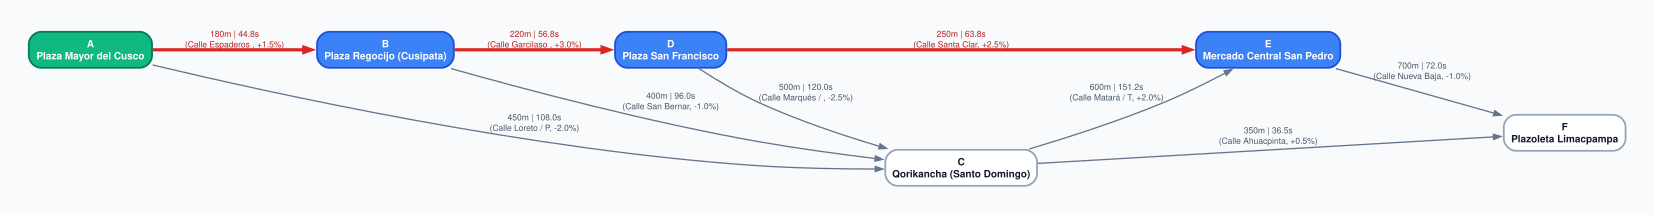

In [15]:
# Renderizado interactivo en Google Colab con la ruta A -> B -> D -> E resaltada
dot_code = generate_cusco_graphviz(metric="time", highlight_path=["A", "B", "D", "E"])
if graphviz_available:
    from IPython.display import display
    display(graphviz.Source(dot_code))
else:
    print("Graphviz no está disponible; se conserva la especificación DOT:")
    print(dot_code)


## 9. Visualizaciones Topográficas y Comparativa de Costos

Complementariamente, representamos la topología ilustrativa y mostramos distancia (m) y tiempo modelado (s) en ejes separados: sus magnitudes no tienen la misma unidad y no se deben comparar directamente.


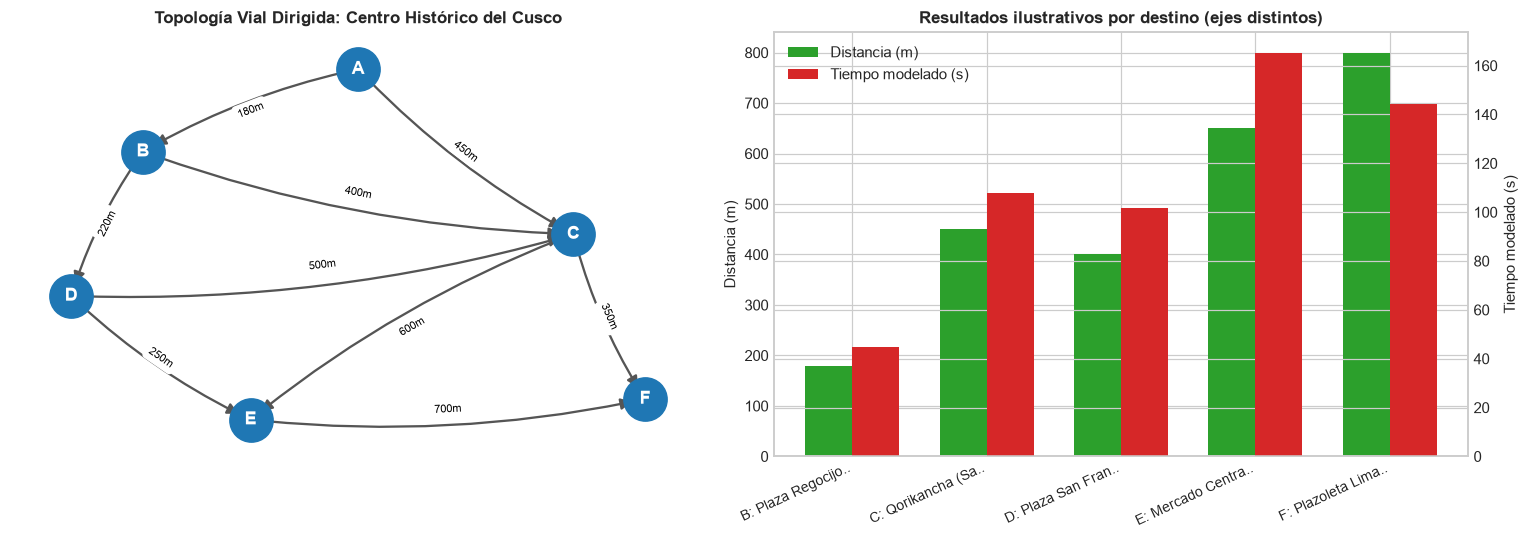

In [16]:
# La figura combina la topología vial con la comparación de métricas.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Grafo vial en plano relativo
# NetworkX representa la red como un grafo dirigido.
G = nx.DiGraph()
for n in nodes:
    G.add_node(n)
for seg in ROAD_SEGMENTS:
    G.add_edge(seg.origin, seg.destination, weight=seg.length_m)

pos = {
    'A': (0.5, 0.9),
    'B': (0.2, 0.7),
    'C': (0.8, 0.5),
    'D': (0.1, 0.35),
    'E': (0.35, 0.05),
    'F': (0.9, 0.1)
}

nx.draw_networkx_nodes(G, pos, ax=ax1, node_color='#1f77b4', node_size=800)
nx.draw_networkx_labels(G, pos, ax=ax1, font_color='white', font_weight='bold')
nx.draw_networkx_edges(G, pos, ax=ax1, edge_color='#555555', arrows=True, arrowsize=15, width=1.5,
                       connectionstyle='arc3,rad=0.08')

edge_labels = {(seg.origin, seg.destination): f"{int(seg.length_m)}m" for seg in ROAD_SEGMENTS}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, ax=ax1, font_size=7.5)
ax1.set_title("Topología Vial Dirigida: Centro Histórico del Cusco", fontsize=11, fontweight='bold')
ax1.axis('off')

# 2. Barras comparativas
# Se excluye el origen para comparar ?nicamente los destinos alcanzables.
dest_nodes = [n for n in nodes if n != source]
dist_vals = [res_bin["distances"][n] for n in dest_nodes]
time_vals = [res_time["distances"][n] for n in dest_nodes]
labels = [f"{n}: {NODES_CUSCO[n][:14]}.." for n in dest_nodes]

x = range(len(dest_nodes))
width = 0.35
ax2.bar([i - width/2 for i in x], dist_vals, width, label='Distancia (m)', color='#2ca02c')
ax_time = ax2.twinx()
ax_time.bar([i + width/2 for i in x], time_vals, width, label='Tiempo modelado (s)', color='#d62728')
ax2.set_xticks(list(x))
ax2.set_xticklabels(labels, rotation=25, ha='right', fontsize=9)
ax2.set_ylabel("Distancia (m)")
ax_time.set_ylabel("Tiempo modelado (s)")
ax2.set_title("Resultados ilustrativos por destino (ejes distintos)", fontsize=11, fontweight='bold')
handles_d, labels_d = ax2.get_legend_handles_labels()
handles_t, labels_t = ax_time.get_legend_handles_labels()
ax2.legend(handles_d + handles_t, labels_d + labels_t)

plt.tight_layout()
plt.show()


## 10. Pruebas Automatizadas con Casos Básicos, Límite y Adversos

Como complemento didáctico a la suite principal de `python/tests/`, ejecutamos comprobaciones de casos básicos, límites y adversos (apartados 6 y 13 de la consigna):
1. **Caso Básico:** Ruteo estándar en red de Cusco.
2. **Caso Límite (Grafo Desconectado):** Componentes inalcanzables con distancia $\infty$.
3. **Caso Límite (Grafo Unitario):** Grafo con un único nodo $|V|=1$.
4. **Caso Límite (Múltiples Caminos Idénticos):** Concurrencia de costos iguales.
5. **Caso Adverso (Origen Inexistente):** Validación de lanzamiento de excepción `ValueError`.
6. **Caso Adverso (Pesos Negativos):** Detección y rechazo estricto según precondición de Dijkstra y $A^*$.
7. **Equivalencia de Colas:** Verificación de igualdad de salida en todas las instancias.
8. **Regresión A*:** Contraejemplo de la heurística antigua: el óptimo es 2, no 51.
9. **Consistencia:** Se verifica $h(u) \le w(u,v)+h(v)$ para ambas métricas y todas las aristas.
10. **Peso no finito:** NaN se rechaza antes de ejecutar Dijkstra.


### 10.1. Casos básicos y límite
Comprobamos distancias conocidas, desconexión, grafo unitario y empates.


In [17]:
test_count = 0
# 1. Caso Básico: Cusco Red
# La red principal comprueba costos conocidos de la instancia de Cusco.
res = dijkstra_solver(nodes, adj_dist, "A")
assert res["distances"]["A"] == 0.0
assert res["distances"]["E"] == 650.0
test_count += 1
print("  [OK] Test 1: Caso básico en red de Cusco verificado.")

# 2. Caso Límite: Grafo Desconectado
# El grafo desconectado comprueba que los nodos inalcanzables conserven infinito.
disc_nodes = ["N1", "N2", "Aislado"]
disc_adj = {"N1": [("N2", 10.0)], "N2": [], "Aislado": []}
res_disc = dijkstra_solver(disc_nodes, disc_adj, "N1")
assert res_disc["distances"]["N2"] == 10.0
assert res_disc["distances"]["Aislado"] == float('inf')
assert res_disc["predecessors"]["Aislado"] is None
test_count += 1
print("  [OK] Test 2: Caso límite con componente desconectado e inalcanzable (infinito) superado.")

# 3. Caso Límite: Grafo Unitario (|V|=1)
single_nodes = ["Solo"]
single_adj = {"Solo": []}
res_single = dijkstra_solver(single_nodes, single_adj, "Solo")
assert res_single["distances"]["Solo"] == 0.0
assert res_single["predecessors"]["Solo"] is None
test_count += 1
print("  [OK] Test 3: Caso límite con grafo unitario (|V|=1) superado.")

# 4. Caso Límite: Múltiples Caminos Idénticos
par_nodes = ["X", "Y1", "Y2", "Z"]
par_adj = {
    "X": [("Y1", 5.0), ("Y2", 5.0)],
    "Y1": [("Z", 5.0)],
    "Y2": [("Z", 5.0)],
    "Z": []
}
res_par = dijkstra_solver(par_nodes, par_adj, "X")
assert res_par["distances"]["Z"] == 10.0
test_count += 1
print("  [OK] Test 4: Caso límite con rutas simétricas de igual costo superado.")


  [OK] Test 1: Caso básico en red de Cusco verificado.
  [OK] Test 2: Caso límite con componente desconectado e inalcanzable (infinito) superado.
  [OK] Test 3: Caso límite con grafo unitario (|V|=1) superado.
  [OK] Test 4: Caso límite con rutas simétricas de igual costo superado.


### 10.2. Entradas adversas y equivalencia de colas
Se rechazan entradas no válidas y se contrastan las tres colas también cuando hay destinos inalcanzables.


In [18]:
# 5. Caso Adverso: Nodo Origen Inexistente
try:
    dijkstra_solver(nodes, adj_dist, "NODO_FANTASMA")
    assert False, "Debería haber fallado"
except ValueError as e:
    assert "no existe en la red" in str(e)
test_count += 1
print("  [OK] Test 5: Caso adverso (origen inválido rechazado con ValueError) superado.")

# 6. Caso Adverso: Arista con Peso Negativo
neg_nodes = ["U", "V"]
neg_adj = {"U": [("V", -15.0)], "V": []}
try:
    dijkstra_solver(neg_nodes, neg_adj, "U")
    assert False, "Debería haber fallado"
except ValueError as e:
    assert "Peso negativo detectado" in str(e)
test_count += 1
print("  [OK] Test 6: Caso adverso (pesos negativos detectados y bloqueados) superado.")

# 7. Equivalencia Cruzada de las 3 Colas en Grafo Complejo
r_bin = dijkstra_solver(nodes, adj_time, "B", queue_type="binary_heap")
r_4ary = dijkstra_solver(nodes, adj_time, "B", queue_type="4ary_heap")
r_fib = dijkstra_solver(nodes, adj_time, "B", queue_type="fibonacci_heap")
for v in nodes:
    d_bin, d_4ary, d_fib = r_bin["distances"][v], r_4ary["distances"][v], r_fib["distances"][v]
    if math.isinf(d_bin):
        assert math.isinf(d_4ary) and math.isinf(d_fib)
    else:
        assert abs(d_bin - d_4ary) < 1e-6 and abs(d_bin - d_fib) < 1e-6
test_count += 1
print("  [OK] Test 7: Equivalencia estricta de las tres colas de prioridad verificada en todos los nodos.")


  [OK] Test 5: Caso adverso (origen inválido rechazado con ValueError) superado.
  [OK] Test 6: Caso adverso (pesos negativos detectados y bloqueados) superado.
  [OK] Test 7: Equivalencia estricta de las tres colas de prioridad verificada en todos los nodos.


### 10.3. Regresión de A* y pesos no finitos
El contraejemplo antiguo y la consistencia se comprueban en ambas métricas; un peso NaN no debe parecer una ruta inalcanzable.


In [19]:
# 8. El A* anterior devolvía 51 en vez de la ruta A-E-F de costo 2.
reg_nodes = list('AECF')
reg_adj = {'A': [('E', 1.0), ('C', 1.0)], 'E': [('F', 1.0)],
           'C': [('F', 50.0)], 'F': []}
reg_coords = {v: COORDS_CUSCO[v] for v in reg_nodes}
astar_reg = a_star_solver(reg_nodes, reg_adj, 'A', 'F', reg_coords)
assert astar_reg['cost'] == dijkstra_solver(reg_nodes, reg_adj, 'A')['distances']['F'] == 2.0
assert astar_reg['path'] == ['A', 'E', 'F']
test_count += 1
print('  [OK] Test 8: A* devuelve el óptimo en el contraejemplo.')

# 9. La escala se calcula por métrica, sobre todas las aristas.
for metric_name in ('distance', 'time'):
    metric_nodes, metric_adj = get_cusco_adjacency(metric_name)
    h, _scale = make_consistent_heuristic(metric_nodes, metric_adj, COORDS_CUSCO, 'F')
    assert h('F') == 0.0
    for u, edges in metric_adj.items():
        for v, weight in edges:
            assert h(u) <= weight + h(v) + 1e-9
test_count += 1
print('  [OK] Test 9: Heurística consistente para metros y segundos.')

# 10. NaN debe rechazarse, no producir un destino falsamente inalcanzable.
try:
    dijkstra_solver(['U', 'V'], {'U': [('V', float('nan'))], 'V': []}, 'U')
    raise AssertionError('Debería rechazar NaN')
except ValueError as exc:
    assert 'no finito' in str(exc)
test_count += 1
print('  [OK] Test 10: Se rechaza NaN.')


  [OK] Test 8: A* devuelve el óptimo en el contraejemplo.
  [OK] Test 9: Heurística consistente para metros y segundos.
  [OK] Test 10: Se rechaza NaN.


In [20]:
assert test_count == 10
print(f"\n===> TODAS LAS PRUEBAS DEL CUADERNO PASARON ({test_count}/10).")



===> TODAS LAS PRUEBAS DEL CUADERNO PASARON (10/10).


## 11. Demostración con una consulta modificable

Se pueden cambiar `origen_demo`, `destino_demo` y `metrica_demo` y ejecutar de nuevo esta celda. La comparación usa la instancia ilustrativa del cuaderno; no implica que se haya realizado una defensa ante el docente. Se comparan **costos** (caminos óptimos distintos pueden tener el mismo costo).


In [21]:
# Modifique estas variables para evaluar cualquier par de la instancia ilustrativa:
# Estas variables permiten cambiar la consulta sin modificar los algoritmos.
origen_demo = "B"     # Plaza Regocijo
destino_demo = "F"    # Plazoleta Limacpampa
metrica_demo = "time" # 'time' o 'distance'

# Se construye la instancia usando la métrica elegida para la demostración.
_, adj_eval = get_cusco_adjacency(metric=metrica_demo)

print(f"=== EVALUACIÓN EN TIEMPO REAL: Origen '{origen_demo}' -> Destino '{destino_demo}' ({metrica_demo}) ===")

# 1. Ejecución con las 3 colas
# Las tres colas deben devolver la misma distancia ?ptima.
res_bin_demo = dijkstra_solver(nodes, adj_eval, origen_demo, queue_type="binary_heap")
res_4ary_demo = dijkstra_solver(nodes, adj_eval, origen_demo, queue_type="4ary_heap")
res_fib_demo = dijkstra_solver(nodes, adj_eval, origen_demo, queue_type="fibonacci_heap")

# 2. Ejecución con A*
# A* se compara con Dijkstra para el mismo origen, destino y métrica.
res_astar_demo = a_star_solver(nodes, adj_eval, origen_demo, destino_demo, coords=COORDS_CUSCO, queue_type="binary_heap", metric=metrica_demo)

costo_dijkstra = res_bin_demo["distances"][destino_demo]
costo_astar = res_astar_demo["cost"]
ruta_dijkstra = (' -> '.join(reconstruct_path(res_bin_demo['predecessors'], destino_demo))
                  if math.isfinite(costo_dijkstra) else '(inalcanzable)')
ruta_astar = ' -> '.join(res_astar_demo['path']) if res_astar_demo['path'] else '(inalcanzable)'

# Verificación de equivalencia
assert math.isclose(costo_dijkstra, res_4ary_demo['distances'][destino_demo], abs_tol=1e-6)
assert math.isclose(costo_dijkstra, res_fib_demo['distances'][destino_demo], abs_tol=1e-6)
assert math.isclose(costo_dijkstra, costo_astar, abs_tol=1e-6)

print(f"\nCosto Óptimo Mínimo: {costo_dijkstra:.2f} {'segundos' if metrica_demo == 'time' else 'metros'}")
print(f"Ruta Calculada (Dijkstra): {ruta_dijkstra}")
print(f"Ruta Calculada (A*):       {ruta_astar}")
print(f"Nodos Expandidos A*:      {res_astar_demo['nodes_expanded']} de {len(nodes)} nodos totales")
print('\nComprobación: las tres colas y A* coinciden en costo para esta consulta.')


=== EVALUACIÓN EN TIEMPO REAL: Origen 'B' -> Destino 'F' (time) ===

Costo Óptimo Mínimo: 132.45 segundos
Ruta Calculada (Dijkstra): B -> C -> F
Ruta Calculada (A*):       B -> C -> F
Nodos Expandidos A*:      4 de 6 nodos totales

Comprobación: las tres colas y A* coinciden en costo para esta consulta.


## 12. Banco de Pruebas Experimental de Escalabilidad

Generamos grafos dirigidos sintéticos con aristas locales y grado saliente medio cercano a 3.5 (no son cuadrículas ni datos OSM). Para cada tamaño $|V| \in [10,500]$ usamos **una** instancia con semilla $100+|V|$, tres calentamientos y 15 mediciones por cola. Reportamos la mediana de tiempo transcurrido (`perf_counter_ns`, en $\mu s$), no tiempo de CPU; no inferimos superioridad estadística ni medimos memoria o caché. Este ejercicio no es el benchmark canónico de `python/data/processed/benchmark_results.json`.


### 12.1. Generador determinista
El árbol inicial hace alcanzables los nodos desde N0. Se agregan aristas locales sin duplicar pares; la semilla fija la instancia, no los tiempos.


In [22]:
# Genera instancias reproducibles de distintos tamaños para medir escalabilidad.
def generate_synthetic_road_network(
    num_nodes: int,
    avg_degree: float = 3.5,
    seed: int = 42
) -> Tuple[List[str], Dict[str, List[Tuple[str, float]]]]:
    # La semilla permite repetir exactamente la misma red sintética.
    rng = random.Random(seed)
    nodes = [f"N{i}" for i in range(num_nodes)]
    adj = {v: [] for v in nodes}
    # Primero se garantiza conectividad básica y después se agregan aristas locales.
    for i in range(1, num_nodes):
        parent = rng.randint(max(0, i - 4), i - 1)
        w = round(rng.uniform(15.0, 300.0), 1)
        adj[nodes[parent]].append((nodes[i], w))
        if rng.random() < 0.6:
            adj[nodes[i]].append((nodes[parent], round(rng.uniform(15.0, 300.0), 1)))
    # avg_degree controla aproximadamente la densidad final del grafo.
    target_edges = int(num_nodes * avg_degree)
    existing = {(u, v) for u, edges in adj.items() for v, _ in edges}
    curr_edges = len(existing)
    attempts = 0
    while curr_edges < target_edges and attempts < target_edges * 5:
        attempts += 1
        u_idx = rng.randint(0, num_nodes - 1)
        delta = rng.choice([-3, -2, -1, 1, 2, 3])
        v_idx = u_idx + delta
        if 0 <= v_idx < num_nodes and u_idx != v_idx:
            u, v = nodes[u_idx], nodes[v_idx]
            if (u, v) not in existing:
                adj[u].append((v, round(rng.uniform(20.0, 450.0), 1)))
                existing.add((u, v))
                curr_edges += 1
    return nodes, adj


### 12.2. Comprobar y medir
Cada red se valida frente a NetworkX antes de medir. Tres calentamientos y 15 tiempos por cola quedan en `benchmark_samples`; solo el solver se cronometra.


In [23]:
# Evaluación experimental
scales = [10, 25, 50, 100, 200, 350, 500]
queues = ["binary_heap", "4ary_heap", "fibonacci_heap"]
benchmark_data = {q: [] for q in queues}
benchmark_samples = {q: {} for q in queues}

print("Ejecutando protocolo de escalabilidad experimental...")
for n in scales:
    s_nodes, s_adj = generate_synthetic_road_network(n, avg_degree=3.5, seed=100 + n)
    src = s_nodes[0]
    validate_graph(s_nodes, s_adj, src)
    reference = nx.single_source_dijkstra_path_length(
        nx.DiGraph((u, v, {'weight': w}) for u, edges in s_adj.items() for v, w in edges), src)
    order = list(queues)
    random.Random(100 + n).shuffle(order)
    for q in order:
        checked = dijkstra_solver(s_nodes, s_adj, src, queue_type=q, validate=False)
        assert all(math.isclose(checked['distances'][v], reference[v], abs_tol=1e-6)
                   for v in s_nodes)
        # Calentamiento (warmup)
        for _ in range(3):
            dijkstra_solver(s_nodes, s_adj, src, queue_type=q, validate=False)
        times = []
        for _ in range(15):
            t0 = time.perf_counter_ns()
            dijkstra_solver(s_nodes, s_adj, src, queue_type=q, validate=False)
            times.append((time.perf_counter_ns() - t0) / 1_000.0)
        benchmark_samples[q][n] = times
        benchmark_data[q].append(statistics.median(times))
    winner = min(queues, key=lambda q: benchmark_data[q][-1])
    print(f"  |V|={n:3d}: Binary={benchmark_data['binary_heap'][-1]:7.1f}µs | 4-ary={benchmark_data['4ary_heap'][-1]:7.1f}µs | Fib={benchmark_data['fibonacci_heap'][-1]:7.1f}µs; menor mediana: {winner}")


Ejecutando protocolo de escalabilidad experimental...
  |V|= 10: Binary=   43.0µs | 4-ary=   46.0µs | Fib=   79.2µs; menor mediana: binary_heap
  |V|= 25: Binary=  116.5µs | 4-ary=  150.5µs | Fib=  198.9µs; menor mediana: binary_heap
  |V|= 50: Binary=  319.3µs | 4-ary=  387.0µs | Fib=  391.2µs; menor mediana: binary_heap
  |V|=100: Binary=  579.6µs | 4-ary=  663.0µs | Fib=  882.2µs; menor mediana: binary_heap


  |V|=200: Binary= 1316.0µs | 4-ary= 1461.1µs | Fib= 2018.6µs; menor mediana: binary_heap


  |V|=350: Binary= 2749.0µs | 4-ary= 2717.8µs | Fib= 3753.8µs; menor mediana: 4ary_heap


  |V|=500: Binary= 3797.1µs | 4-ary= 4065.4µs | Fib= 5821.0µs; menor mediana: binary_heap


### 12.3. Visualizar medianas
La menor mediana observada no implica superioridad universal ni prueba significación estadística.


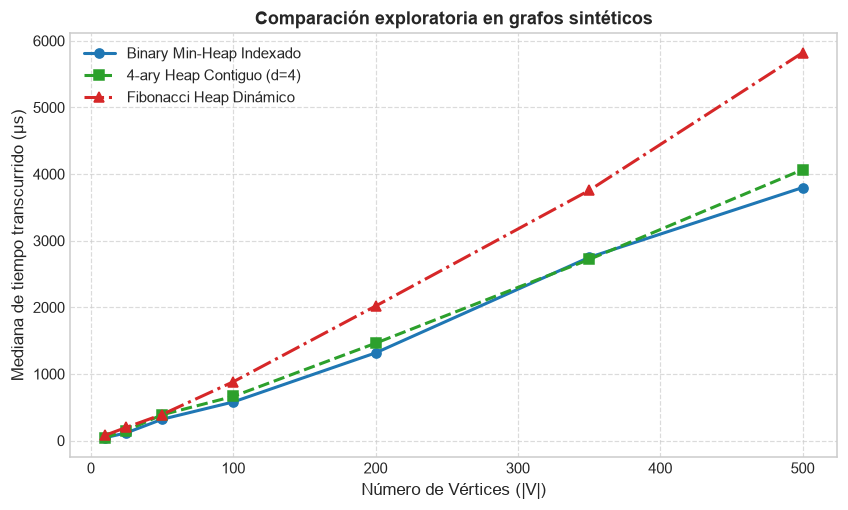

In [24]:
# Gráfico de escalabilidad
plt.figure(figsize=(9, 5))
plt.plot(scales, benchmark_data["binary_heap"], 'o-', label='Binary Min-Heap Indexado', color='#1f77b4', linewidth=2)
plt.plot(scales, benchmark_data["4ary_heap"], 's--', label='4-ary Heap Contiguo (d=4)', color='#2ca02c', linewidth=2)
plt.plot(scales, benchmark_data["fibonacci_heap"], '^-.', label='Fibonacci Heap Dinámico', color='#d62728', linewidth=2)
plt.xlabel("Número de Vértices (|V|)", fontsize=11)
plt.ylabel("Mediana de tiempo transcurrido (µs)", fontsize=11)
plt.title("Comparación exploratoria en grafos sintéticos", fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


## 13. Discusión Técnica, Dificultades Encontradas y Trabajo Futuro

### Hallazgos del Rendimiento Experimental
1. **Resultados de este cuaderno:** Las medianas por tamaño se imprimen y grafican en la celda anterior; su orden puede cambiar según la máquina y la ejecución. En las salidas históricas antes de esta corrección, 4-ary obtuvo la menor media en 1 de 7 tamaños (200), no en todos los tamaños grandes. Esas salidas se sustituyen al ejecutar el cuaderno actualizado.
2. **Complejidad frente a medición:** El 4-ario tiene menor altura pero examina hasta cuatro hijos por nivel; Fibonacci ofrece `decrease_key` amortizado $O(1)$ y Dijkstra $O(E+V\log V)$, sin garantizar menor tiempo en Python. No medimos fallos de caché ni asignaciones; no pueden explicarse causalmente las diferencias con estos datos.
3. **Alcance:** Es una sola instancia por tamaño, con 15 repeticiones del mismo grafo, sin intervalos de confianza. El experimento canónico independiente (`python/data/processed/benchmark_results.json`, 28/10/2026) usa perfiles disperso y denso, varias instancias y 1350 muestras. El piloto posterior del 04/11/2026 tiene 18 muestras; no debe presentarse como anterior al banco.

### Decisiones técnicas y límites verificables
1. **Supuestos del modelo:** $\alpha=2.5$, velocidades, pendientes, topología y coordenadas son ilustrativos, no calibrados con viajes reales.
2. **Corrección documentada:** La heurística anterior suponía erróneamente que toda arista era al menos tan larga como la separación euclidiana; la prueba de regresión muestra el fallo y la escala por arista lo evita. El mapa de posiciones se actualiza en cada `_swap` de los montículos indexados.
3. **Nodos inalcanzables:** Dijkstra deja distancia $\infty$ en un grafo desconectado; los pesos negativos y no finitos se rechazan. Las pruebas de la celda 10 documentan esos casos, no una defensa individual.

### Funcionalidades Futuras Planificadas
- Importar al cuaderno el snapshot OSM ya usado por el proyecto principal, si se quiere enseñar ese caso sin duplicar el benchmark.
- Obtener mediciones verificables de pendiente y tráfico por arista para un futuro modelo calibrado; no están disponibles en este ejemplo.
